# Global and Sequential Comparison

Compare $N_{\mathrm{greedy}}^{\mathrm{seq}}$, $N_{\min}^{\mathrm{seq}}$, and $N_{\min}^{\mathrm{global}}$ on the saved one- and two-dimensional datasets. This notebook runs independently from the inputs.


## Saved-result reuse

With `REUSE_SAVED_RESULTS = True`, matching DP results from 01 or earlier 02/03 runs are reused. Missing or stale cases are solved normally. Metadata, input freshness or hashes, and allocation feasibility are checked. Let 01 finish first for maximum reuse; neither notebook requires it.

Greedy and the global integer program are solved for every selected case.


## Budgets

The global integer-program minimum is

$$N_{\min}^{\mathrm{global}}=\min_{\boldsymbol n\in\mathbb Z_{\geq0}^M}\sum_m n_m,
\qquad \sum_m n_m|r_{ijm}|\geq\pi\quad\text{for every }i<j.$$

Here $r_{ijm}$ is the principal phase gap. Sequential DP gives $N_{\min}^{\mathrm{seq}}$; Greedy gives $N_{\mathrm{greedy}}^{\mathrm{seq}}$. Each case satisfies
$N_{\min}^{\mathrm{global}}\leq N_{\min}^{\mathrm{seq}}\leq N_{\mathrm{greedy}}^{\mathrm{seq}}$.

The global minimum refers to this integer program; its constraints alone do not certify a shared global input state. HiGHS uses zero relative MIP gap and $10^{-9}$ feasibility tolerances; allocations are independently checked to $10^{-8}$ after normalization by $\pi$.


In [12]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

working_directory = Path.cwd().resolve()
PROJECT_DIRECTORY = (
    working_directory / "problem-1-zero-error"
    if (working_directory / "problem-1-zero-error").is_dir()
    else working_directory
)
SOURCE_DIRECTORY = PROJECT_DIRECTORY / "src"
if str(SOURCE_DIRECTORY) not in sys.path:
    sys.path.insert(0, str(SOURCE_DIRECTORY))
for module in ("run_config", "sensor_budget_analysis", "lower_bound", "phase_data", "optimal", "eval"):
    sys.modules.pop(module, None)
from sensor_budget_analysis import (
    run_budget_analysis, plot_budget_comparison, configure_style, save_figure,
)
print("Project directory:", PROJECT_DIRECTORY)


Project directory: /Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/problem-1-zero-error


## Run configuration

Set `RUN_MODE` to `"test"` (132 cases: all families and K, M=3 or 6, replicate 1) or `"full"` (39,600 cases). Run all cells after changing it. Test and full outputs are separate; final figures use full results.


In [13]:
RUN_MODE = "full"  # "test" or "full"
REUSE_SAVED_RESULTS = True  # False forces a fresh DP solve for every selected case.

if RUN_MODE not in ("test", "full"):
    raise ValueError('RUN_MODE must be "test" or "full"')
print("Run mode:", RUN_MODE)
print("Expected standard benchmark cases:", 132 if RUN_MODE == "test" else 39_600)


Run mode: full
Expected standard benchmark cases: 39600


## Compute budgets


In [14]:
analysis = run_budget_analysis(
    PROJECT_DIRECTORY, include_lower_bound=True, run_mode=RUN_MODE,
    reuse_saved=REUSE_SAVED_RESULTS,
)
rows = analysis["rows"]
summary = analysis["summary"]
OUTPUT_DIRECTORY = analysis["output_directory"]
assert all(row["N_LB"] <= row["N_min"] <= row["N_greedy"] for row in rows)
print(f"Verified all {len(rows):,} paired instances.")
print("Output:", OUTPUT_DIRECTORY)

Run mode: full; selected 39,600 cases
benchmark_1d: 1/19,800 cases; 2.2s elapsed
benchmark_1d: 500/19,800 cases; 2.8s elapsed
benchmark_1d: 1,000/19,800 cases; 6.2s elapsed
benchmark_1d: 1,500/19,800 cases; 10.2s elapsed
benchmark_1d: 2,000/19,800 cases; 14.0s elapsed
benchmark_1d: 2,500/19,800 cases; 18.0s elapsed
benchmark_1d: 3,000/19,800 cases; 23.1s elapsed
benchmark_1d: 3,500/19,800 cases; 27.6s elapsed
benchmark_1d: 4,000/19,800 cases; 32.7s elapsed
benchmark_1d: 4,500/19,800 cases; 38.3s elapsed
benchmark_1d: 5,000/19,800 cases; 44.9s elapsed
benchmark_1d: 5,500/19,800 cases; 52.6s elapsed
benchmark_1d: 6,000/19,800 cases; 61.9s elapsed
benchmark_1d: 6,500/19,800 cases; 69.6s elapsed
benchmark_1d: 7,000/19,800 cases; 73.1s elapsed
benchmark_1d: 7,500/19,800 cases; 75.7s elapsed
benchmark_1d: 8,000/19,800 cases; 79.5s elapsed
benchmark_1d: 8,500/19,800 cases; 83.2s elapsed
HighsMipSolverData::transformNewIntegerFeasibleSolution tmpSolver.run();
HighsMipSolverData::transformNewIn

## Budget summary

All three curves average the same cases, pooling families and M at each K: 1,800 cases per dimension in full mode, 6 in test mode. The fixed-K,M table keeps location counts separate.


In [15]:
def show_summary(rows, include_lb=False):
    header = r"| Dimension | K | Cases | Mean $N_{\min}^{\mathrm{seq}}$ |"
    separator = "|---|---:|---:|---:|"
    if include_lb:
        header += r" Mean $N_{\mathrm{greedy}}^{\mathrm{seq}}$ | Mean $N_{\min}^{\mathrm{global}}$ | Mean gap | Equal budgets (%) |"
        separator += "---:|---:|---:|---:|"
    lines = [header, separator]
    for row in rows:
        line = (f"| {row['dimension']} | {row['K']} | {row['case_count']} | "
                f"{row['mean_N_min_opt']:.3f} |")
        if include_lb:
            line += (f" {row['mean_N_greedy']:.3f} | {row['mean_N_LB']:.3f} | {row['mean_sensor_gap']:.3f} | "
                     f"{100 * row['equal_budget_fraction']:.1f} |")
        lines.append(line)
    display(Markdown("\n".join(lines)))

show_summary(summary, include_lb=True)

| Dimension | K | Cases | Mean $N_{\min}^{\mathrm{seq}}$ | Mean $N_{\mathrm{greedy}}^{\mathrm{seq}}$ | Mean $N_{\min}^{\mathrm{global}}$ | Mean gap | Equal budgets (%) |
|---|---:|---:|---:|---:|---:|---:|---:|
| 1D | 2 | 1800 | 8.093 | 8.093 | 8.093 | 0.000 | 100.0 |
| 1D | 3 | 1800 | 16.051 | 17.328 | 15.218 | 0.833 | 56.8 |
| 1D | 4 | 1800 | 24.238 | 26.606 | 22.154 | 2.083 | 33.7 |
| 1D | 5 | 1800 | 31.321 | 34.798 | 28.021 | 3.301 | 23.9 |
| 1D | 6 | 1800 | 38.676 | 43.424 | 34.127 | 4.549 | 19.5 |
| 1D | 7 | 1800 | 45.769 | 51.572 | 39.867 | 5.903 | 16.6 |
| 1D | 8 | 1800 | 52.503 | 58.966 | 45.165 | 7.338 | 13.3 |
| 1D | 9 | 1800 | 60.983 | 69.245 | 52.450 | 8.533 | 13.1 |
| 1D | 10 | 1800 | 66.341 | 74.985 | 56.349 | 9.992 | 11.2 |
| 1D | 11 | 1800 | 71.896 | 81.124 | 60.528 | 11.368 | 10.6 |
| 1D | 12 | 1800 | 78.033 | 87.708 | 65.408 | 12.626 | 10.2 |
| 2D | 2 | 1800 | 9.255 | 9.255 | 9.255 | 0.000 | 100.0 |
| 2D | 3 | 1800 | 19.757 | 21.147 | 18.818 | 0.938 | 52.2 |
| 2D | 4 | 1800 | 28.296 | 30.907 | 25.856 | 2.439 | 30.3 |
| 2D | 5 | 1800 | 38.201 | 42.285 | 34.195 | 4.006 | 22.0 |
| 2D | 6 | 1800 | 46.988 | 52.302 | 41.152 | 5.836 | 16.1 |
| 2D | 7 | 1800 | 55.379 | 61.779 | 47.926 | 7.454 | 13.7 |
| 2D | 8 | 1800 | 61.915 | 69.072 | 52.161 | 9.754 | 11.6 |
| 2D | 9 | 1800 | 71.438 | 79.721 | 59.525 | 11.913 | 10.4 |
| 2D | 10 | 1800 | 78.849 | 88.079 | 65.096 | 13.753 | 9.4 |
| 2D | 11 | 1800 | 85.288 | 95.361 | 69.664 | 15.623 | 9.3 |
| 2D | 12 | 1800 | 91.232 | 102.879 | 73.849 | 17.383 | 8.9 |

## Budget comparison


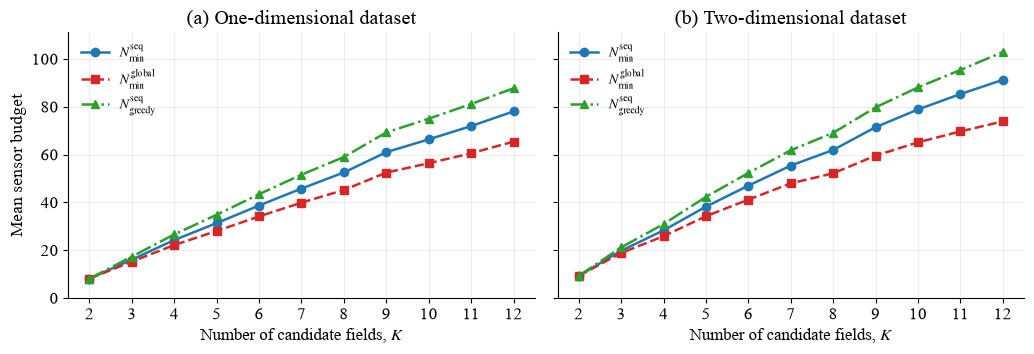

In [16]:
figure = plot_budget_comparison(summary)
if RUN_MODE == "test":
    figure.suptitle(f"Test run: {len(rows):,} cases (subset of benchmark)")
    figure.tight_layout(rect=(0, 0, 1, 0.94))
save_figure(figure, OUTPUT_DIRECTORY / "figures", "nlb_vs_nmin_by_k")
display(figure)
plt.close(figure)

## Saved outputs

Results go to `results/lb/{test,full}/`. `tables/case_budgets.csv` stores budgets, allocations, timings, and diagnostics. `nlb_vs_nmin_by_dimension_k.csv` and `nlb_vs_nmin_by_k_m.csv` contain summaries; `figures/nlb_vs_nmin_by_k.{pdf,png}` contains the comparison. Existing filenames are retained for compatibility. Final figures read the full summary.
